# Week 4 Day 1: Descriptive Statistics
Dataset: retail sales data.
Goal: summarise sales, study distribution shape, calculate quartiles, and compare groups.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

data_path = Path("../../week-01/day-05/sales_data.csv")
df = pd.read_csv(data_path)
df.head()

,sale_id,customer_name,product,category,region,amount,sale_date,discount
0,1,Ananya,Laptop,Electronics,South,55000,01-09-2026,0.10
1,2,Rahul,Phone,Electronics,North,25000,02-09-2026,0.05
2,3,Priya,Chair,Furniture,West,4500,03-09-2026,NaN
3,4,Arjun,Desk,Furniture,South,8000,04-09-2026,0.00
4,5,Meera,Headphones,Electronics,East,2000,05-09-2026,0.15


In [2]:
print("Dataset shape:", df.shape)
print(df.dtypes)
print("\\nMissing values:")
print(df.isna().sum())

Dataset shape: (10, 8)
sale_id            int64
customer_name        str
product              str
category             str
region               str
amount             int64
sale_date            str
discount         float64
dtype: object
\nMissing values:
sale_id          0
customer_name    0
product          0
category         0
region           0
amount           0
sale_date        0
discount         3
dtype: int64


## Mean, median, mode, variance, and standard deviation

In [3]:
sales = pd.to_numeric(df["amount"], errors="coerce").dropna()
mode_values = sales.mode()
stats = {
    "Mean": sales.mean(),
    "Median": sales.median(),
    "Mode": ", ".join(map(str, mode_values.tolist())) if not mode_values.empty else "No mode",
    "Sample variance": sales.var(),
    "Sample standard deviation": sales.std(),
    "Minimum": sales.min(),
    "Maximum": sales.max(),
    "Range": sales.max() - sales.min()
}
pd.DataFrame.from_dict(stats, orient="index", columns=["Value"])

,Value
Mean,13120.0
Median,7250.0
Mode,"50, 150, 2000, 4500, 6500, 8000, 12000, 18000,..."
Sample variance,280797888.888889
Sample standard deviation,16757.025061
Minimum,50
Maximum,55000
Range,54950


The mean is the average, the median is the middle value, and the mode is the most frequent value. Standard deviation describes spread in the original sales units.

## Frequency distribution

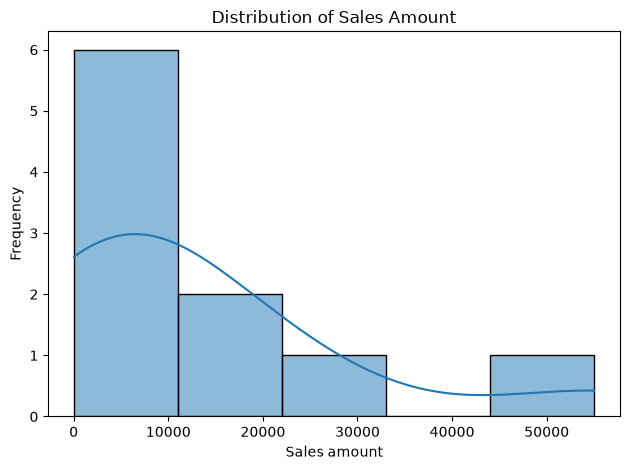

Skewness: 2.019
Likely right-skewed.
Use the histogram too; a small dataset cannot reliably establish normality or bimodality.


In [4]:
sns.histplot(sales, bins="auto", kde=True)
plt.title("Distribution of Sales Amount")
plt.xlabel("Sales amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

skew = sales.skew()
print(f"Skewness: {skew:.3f}")
if skew >= 0.5:
    print("Likely right-skewed.")
elif skew <= -0.5:
    print("Likely left-skewed.")
else:
    print("Approximately symmetric by a simple skewness rule.")
print("Use the histogram too; a small dataset cannot reliably establish normality or bimodality.")

## Percentiles and quartiles

In [5]:
quantiles = sales.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
quantiles.index = ["10th percentile", "Q1 (25%)", "Median (50%)", "Q3 (75%)", "90th percentile", "95th percentile"]
display(quantiles.to_frame("Sales amount"))
q1, q3 = sales.quantile([0.25, 0.75])
print(f"IQR (Q3 - Q1): {q3 - q1:.2f}")

,Sales amount
10th percentile,140.0
Q1 (25%),2625.0
Median (50%),7250.0
Q3 (75%),16500.0
90th percentile,28000.0
95th percentile,41500.0


IQR (Q3 - Q1): 13875.00


## Compare groups using box plots

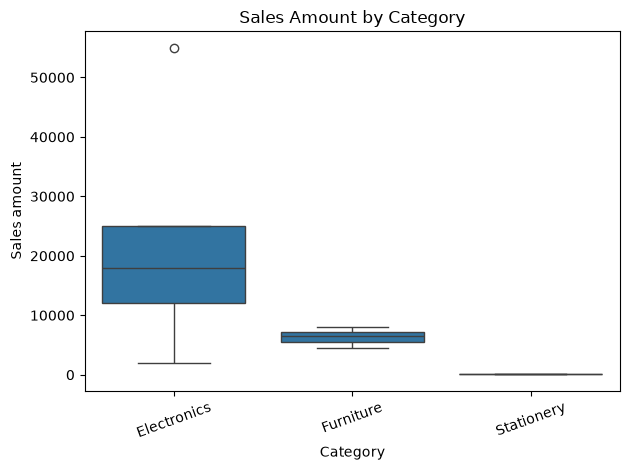

,count,mean,median,std,min,max
category,,,,,,
Electronics,5,22400.000000,18000.0,20082.330542,2000,55000
Furniture,3,6333.333333,6500.0,1755.942292,4500,8000
Stationery,2,100.000000,100.0,70.710678,50,150


In [6]:
group = "category" if df["category"].nunique() >= 2 else "region"
plot_df = df[[group, "amount"]].copy()
plot_df["amount"] = pd.to_numeric(plot_df["amount"], errors="coerce")
plot_df = plot_df.dropna()
sns.boxplot(data=plot_df, x=group, y="amount")
plt.title(f"Sales Amount by {group.title()}")
plt.xlabel(group.title())
plt.ylabel("Sales amount")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
display(plot_df.groupby(group)["amount"].agg(["count", "mean", "median", "std", "min", "max"]))

## Business interpretation
- A gap between mean and median can suggest skew or unusually large sales.
- Higher standard deviation means greater variability in sales amounts.
- Quartiles divide sorted data into four parts; the IQR describes the middle 50%.
- Histograms show distribution shape; box plots compare group medians, spread, and possible outliers.
- Treat conclusions cautiously because this is a small sample.

## Viva notes
1. Mean = average, median = middle value, mode = most frequent value.
2. Standard deviation describes variation around the mean, in the same units as the data.
3. A normal distribution is approximately symmetric and bell-shaped. Inspect a histogram or Q-Q plot, and do not claim normality from a small sample alone.